In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import cv2

In [15]:
df = pd.read_csv("../data/raw/airbus-ship-detection/airbus-ship-detection/train_ship_segmentations_v2.csv")

In [16]:
df.head()

,ImageId,EncodedPixels
0,00003e153.jpg,NaN
1,0001124c7.jpg,NaN
2,000155de5.jpg,264661 17 265429 33 266197 33 266965 33 267733...
3,000194a2d.jpg,360486 1 361252 4 362019 5 362785 8 363552 10 ...
4,000194a2d.jpg,51834 9 52602 9 53370 9 54138 9 54906 9 55674 ...


In [75]:
def rle_decode(mask_rle, shape=(768, 768)):
    if pd.isna(mask_rle):
        return np.zeros(shape, dtype=np.uint8)
    s = mask_rle.split()
    starts = np.asarray(s[0::2], dtype=int) - 1
    lengths = np.asarray(s[1::2], dtype=int)
    ends = starts + lengths
    img = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    for lo, hi in zip(starts, ends):
        img[lo:hi] = 1
    return img.reshape(shape, order='F')

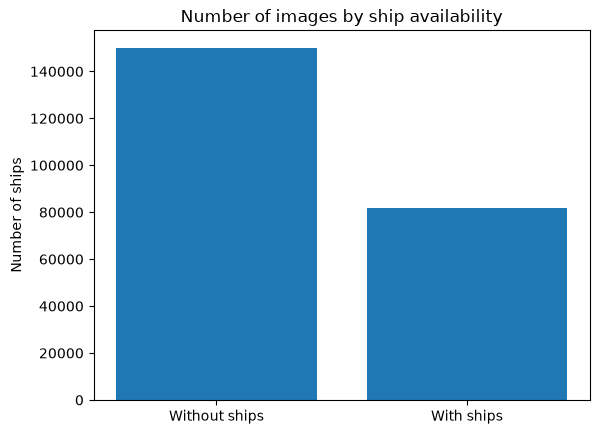

In [17]:
ships_on_image = np.sum(df['EncodedPixels'].isna())
no_ships_on_image = np.sum(~df['EncodedPixels'].isna())

categories = ['Without ships', 'With ships']
plt.bar(categories, [ships_on_image, no_ships_on_image])
plt.title("Number of images by ship availability")
plt.ylabel("Number of ships")
plt.show()

In [18]:
ships = df[df['EncodedPixels'].notna()].copy()
ships.head()

,ImageId,EncodedPixels
2,000155de5.jpg,264661 17 265429 33 266197 33 266965 33 267733...
3,000194a2d.jpg,360486 1 361252 4 362019 5 362785 8 363552 10 ...
4,000194a2d.jpg,51834 9 52602 9 53370 9 54138 9 54906 9 55674 ...
5,000194a2d.jpg,198320 10 199088 10 199856 10 200624 10 201392...
6,000194a2d.jpg,55683 1 56451 1 57219 1 57987 1 58755 1 59523 ...


In [20]:
ships_per_image = ships.groupby('ImageId').size().reset_index(name='ship_count')
ships_per_image.head()

,ImageId,ship_count
0,000155de5.jpg,1
1,000194a2d.jpg,5
2,00021ddc3.jpg,9
3,0002756f7.jpg,2
4,00031f145.jpg,1


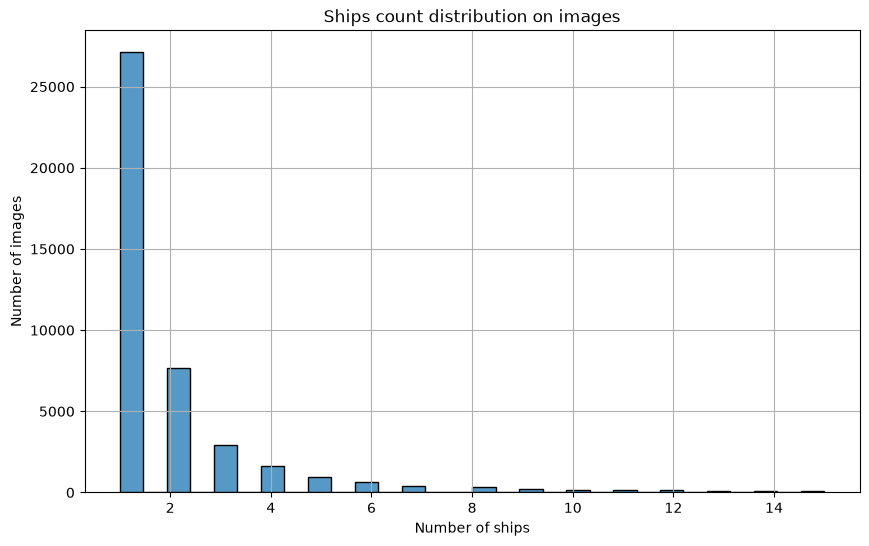

In [27]:
plt.figure(figsize=(10, 6))
sns.histplot(ships_per_image['ship_count'], bins=30, kde=False)
plt.title('Ships count distribution on images')
plt.xlabel('Number of ships')
plt.ylabel('Number of images')
plt.grid()
plt.show()

In [ ]:
def rle_area(rle_str):
    if pd.isna(rle_str):
        return 0
    lengths = [int(x) for x in rle_str.split()[1::2]]  # каждое второе значение — длина
    return sum(lengths)

ships['area'] = ships['EncodedPixels'].apply(rle_area)

print(ships['area'].describe())
print(f"Медианная площадь: {ships['area'].median()}")
print(f"Максимальная площадь: {ships['area'].max()}")

count    81723.000000
mean      1567.402849
std       2842.081203
min          2.000000
25%        111.000000
50%        408.000000
75%       1550.000000
max      25904.000000
Name: area, dtype: float64
Медианная площадь: 408.0
Максимальная площадь: 25904


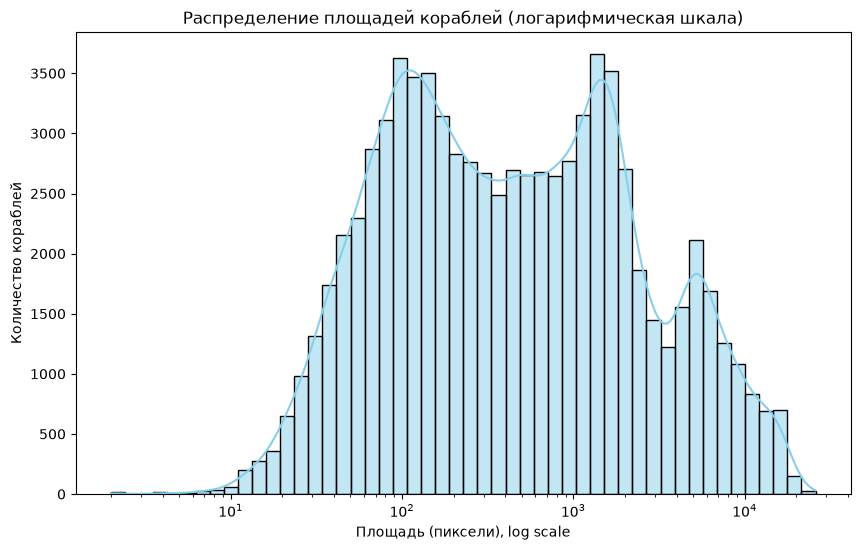

In [30]:
plt.figure(figsize=(10, 6))
sns.histplot(ships['area'], bins=50, log_scale=True, kde=True, color='skyblue')
plt.title('Распределение площадей кораблей (логарифмическая шкала)')
plt.xlabel('Площадь (пиксели), log scale')
plt.ylabel('Количество кораблей')
plt.show()

In [42]:
ships_df = df[df['EncodedPixels'].notna()].copy()
no_ships_df = df[df['EncodedPixels'].isna()].copy()

ship_image_ids = ships_df['ImageId'].unique()
no_ship_image_ids = no_ships_df['ImageId'].unique()

num_with_ships = 5
num_without_ships = 5

np.random.seed(42)

In [68]:
selected_with = np.random.choice(ship_image_ids, size=num_with_ships)
selected_without = np.random.choice(no_ship_image_ids, size=num_without_ships)

selected_images = np.hstack((selected_with, selected_without))

print(selected_with, "\n", selected_without)
selected_images

['81726aca3.jpg' '869c8cd99.jpg' '8d1fe581c.jpg' 'f9cf9a6d6.jpg'
 '86e5d743b.jpg'] 
 ['fea5a9fd9.jpg' 'b499662bc.jpg' '6ac70b800.jpg' '80cd0b305.jpg'
 '9f893974b.jpg']


array(['81726aca3.jpg', '869c8cd99.jpg', '8d1fe581c.jpg', 'f9cf9a6d6.jpg',
       '86e5d743b.jpg', 'fea5a9fd9.jpg', 'b499662bc.jpg', '6ac70b800.jpg',
       '80cd0b305.jpg', '9f893974b.jpg'], dtype=object)

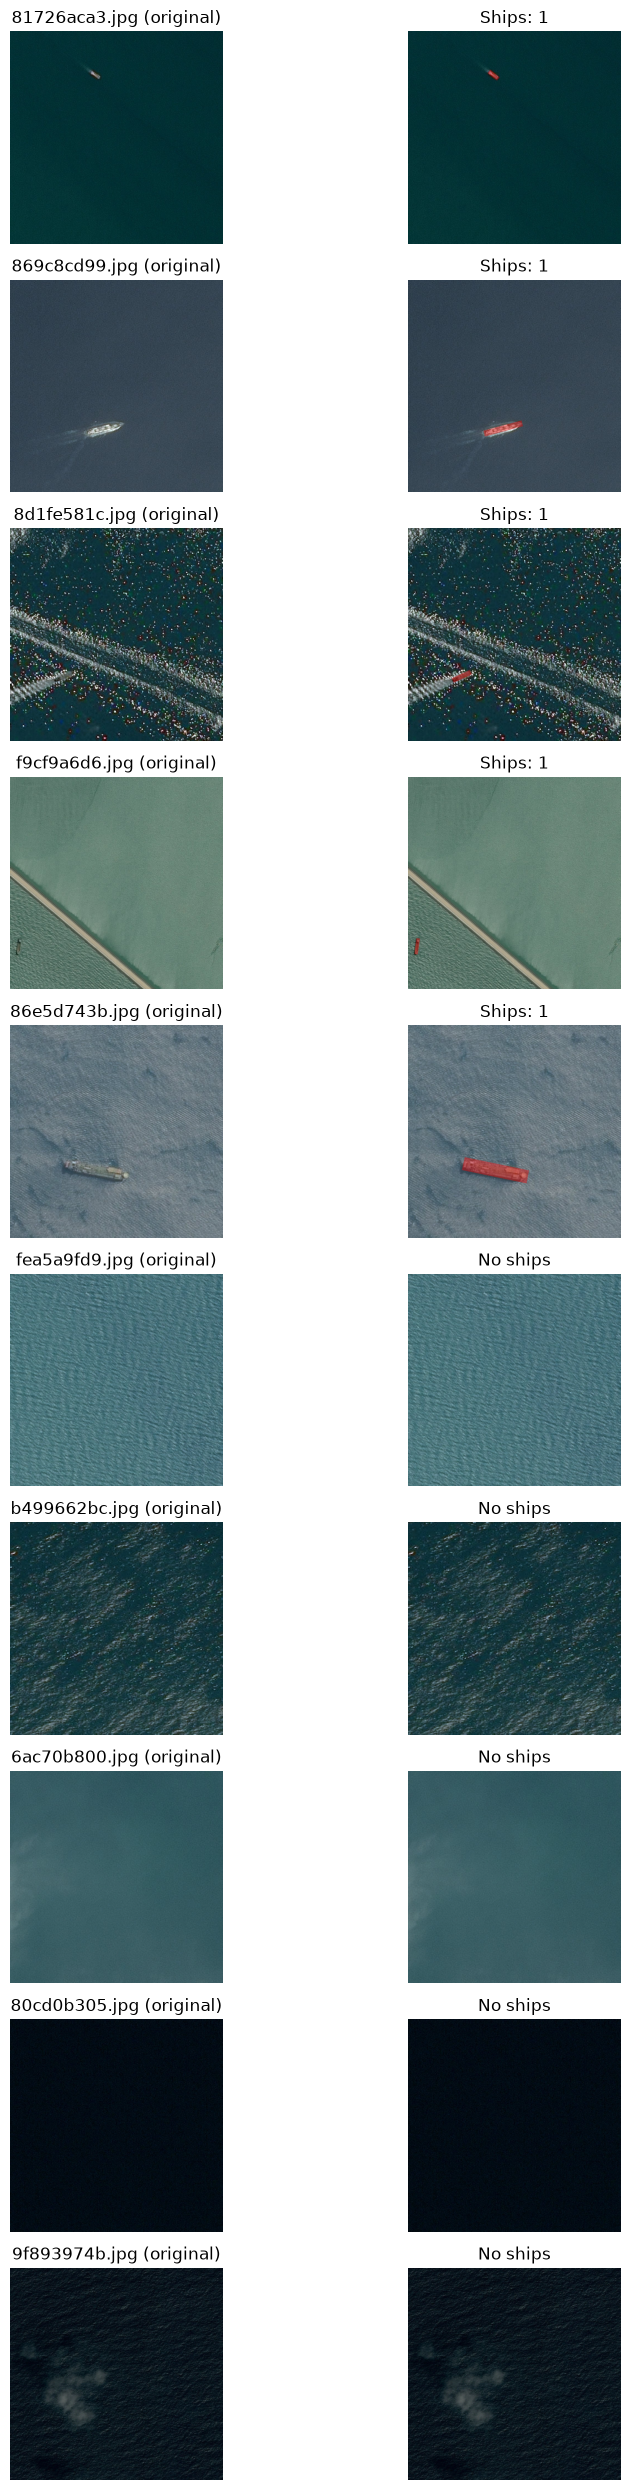

In [76]:
fig, axes = plt.subplots(len(selected_images), 2, figsize=(10, 2.5 * len(selected_images)))

for idx, image_id in enumerate(selected_images):
    img_path = os.path.join('../data/raw/airbus-ship-detection/airbus-ship-detection/train_v2', image_id)
    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # конвертация в RGB для matplotlib

    # Получаем маску(и) для этого изображения
    masks_rle = df[df['ImageId'] == image_id]['EncodedPixels'].values
    full_mask = np.zeros((768, 768), dtype=np.uint8)
    for rle in masks_rle:
        if pd.notna(rle):
            mask = rle_decode(rle, (768, 768))
            full_mask = np.maximum(full_mask, mask)  # объединение всех кораблей

    # Наложение маски
    overlay = image.copy()
    overlay[full_mask == 1] = [255, 0, 0]  # красный цвет для кораблей
    blended = cv2.addWeighted(image, 0.6, overlay, 0.4, 0)

    # Отображение
    ax1 = axes[idx, 0]
    ax2 = axes[idx, 1]
    ax1.imshow(image)
    ax1.set_title(f'{image_id} (original)')
    ax1.axis('off')

    ax2.imshow(blended)
    if full_mask.sum() > 0:
        ax2.set_title(f'Ships: {int(full_mask.sum() > 0)}')
    else:
        ax2.set_title('No ships')
    ax2.axis('off')


plt.tight_layout()
plt.show()

In [59]:
img_path = os.path.join('../data/raw/airbus-ship-detection/airbus-ship-detection/train_v2', image_id)
img_path

'../data/raw/airbus-ship-detection/airbus-ship-detection/train_v2/1572c4143.jpg950281e08.jpg'